In [1]:
# Libraries:
import numpy as np
import matplotlib.pyplot as plt
import dill
import sys
import os

import pysindy as ps
import D_CODE

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..'))) # include parent directory in the path
from data import SINDy_data
from data import data
from data import equations

from toolbox.auxiliary_functions import SRT_simulation, D_CODE_simulation, set_param_freq

# Seed:
np.random.seed(999)

/home/mattg/miniforge3/envs/SimbSINDy_env/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


#### Case $k$ varying and $n$, $k_a$, $k_y$ fixed
Consider the modified Van der Pol system with a nonlinear forcing term
$$
\begin{cases}
\dot{x} = \frac{k y^n}{k_a + y^n} \\
\dot{y} = - k_y y
\end{cases}
$$
and with $n=2.8$, $k_a=4$ and $k_y=0.1$ fixed, and $k \in [1,2]$

In [2]:
# Select ODE & settings:
ode_name = 'HillODE_par_k' # help="name of the ode", type=str
ode_param = '2.8,4,0.1' # help="parameters of the ode (default: None)", type=str, default=None
freq = 10 # help="sampling frequency", type=float, default=10
n_sample = 50 # help="number of trajectories", type=int, default=100
noise_ratio = 0.01 # help="noise level (default 0)", type=float, default=0.
seed = 102 # help="random seed", type=int, default=0
n_seed = 1 # help="random seed", type=int, default=10

ode_param, freq = set_param_freq(ode_param, freq)

ode = equations.get_ode(ode_name, ode_param)
dt = 1 / freq
dim_x = 2
dim_k = 1
time_vector = np.arange(0, ode.T + dt, dt)
T = ode.T

#### SR-T run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Hill ODE.

In [3]:
# running SR-T:
building_blocks_lambda0, function_names0 = SRT_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = SRT_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, alg='tv', seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=HillODE_par_k, ode_param=[2.8, 4.0, 0.1], x_id=0, freq=10, n_sample=50, noise_sigma=0.01, alg=tv, seed=102, n_seed=1
Dataset shape:  (151, 50, 3)
Functions set:  {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    10.75      3.23885e+10       11         0.213208         0.203049      3.94m


/home/mattg/gplearn/gplearn/functions.py:132: RuntimeWarning: overflow encountered in power
  return np.where(np.logical_and(np.minimum(x1, x2) >= 0, np.maximum(x1, x2) <= 10), np.power(x1, x2), 1000)
/home/mattg/gplearn/gplearn/functions.py:132: RuntimeWarning: overflow encountered in power
  return np.where(np.logical_and(np.minimum(x1, x2) >= 0, np.maximum(x1, x2) <= 10), np.power(x1, x2), 1000)


   1     6.29          7375.66       11         0.211317         0.220074      4.94m
   2     3.69          50711.6        9         0.179862         0.180443      3.35m
   3     4.57          17874.1       19         0.111312         0.107372      3.00m
   4     6.96          12153.5        9        0.0946299        0.0994102      3.10m
   5     7.32          18648.1        9        0.0634883        0.0650134      3.05m
   6     7.66          12879.7       11        0.0631677        0.0674499      2.53m
   7     7.77          9163.95        9        0.0631306        0.0660537      2.20m
   8     8.65      1.15985e+06       11        0.0299552        0.0312191      2.25m
   9     9.11          3268.31       11        0.0299193        0.0315419      1.96m
  10     9.10          40320.2       11        0.0290708        0.0299881      1.94m
  11     9.19      1.16361e+07       11        0.0289717        0.0308809      1.70m
  12     9.67          2050.42       11        0.0264701        0

##### Plot per report

In [ ]:
from report import evaluate_traj, SRModel_param

# Define the Symbolic Regression model cohirently with the SINDy model
f = lambda x,t,k: [
    x[1]*k/(x[1] + 3.9884259646106344*x[1]**(-1.763573077599074)),
    -0.10018477335405253 * x[1]
]
model = SRModel_param(f)

In [4]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [10., 10., 2.], [0., 0., 1.], dim_k)
print('SR_T Model RMSE: ', rmse)

SR_T Model RMSE:  0.01636382214551358


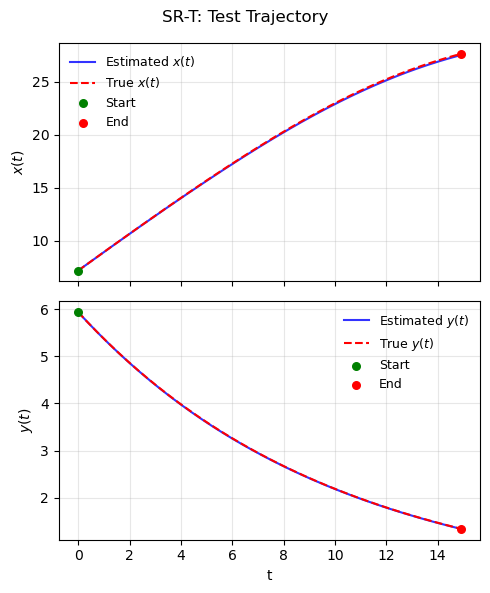

In [ ]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [7., 6., 1.8]
title = 'SR-T: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

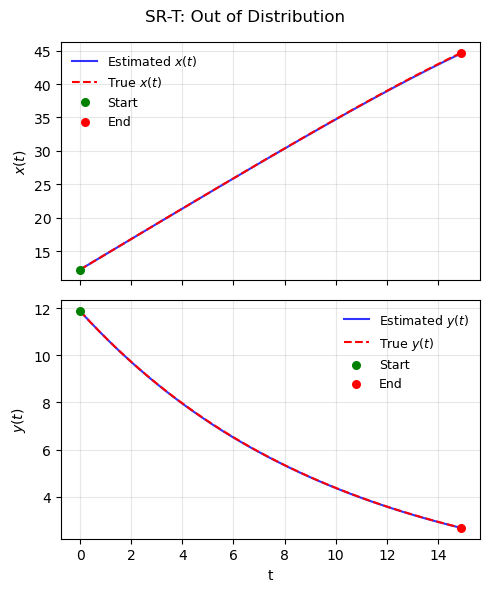

In [ ]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [12, 12, 2.3]
title = 'SR-T: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

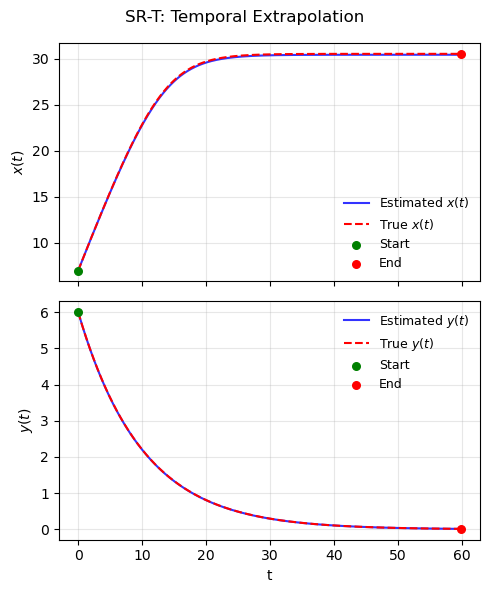

In [9]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [7, 6, 1.8]
title = 'SR-T: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=60)

#### D-CODE run

> **Remark.** Before running the experiments, make sure that the following settings are correctly configured in the `D_CODE` library:
>
> * In `config.py`, set:
>
>   ```python
>   n_generations = 20
>   functions_set = {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
>   ```
> * In `gp_utils.py`, uncomment the line of code responsible for extracting the Hill ODE.

In [3]:
# running D-CODE
building_blocks_lambda0, function_names0 = D_CODE_simulation(ode_name, ode_param, 0, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)
building_blocks_lambda1, function_names1 = D_CODE_simulation(ode_name, ode_param, 1, freq, n_sample, noise_ratio, seed=seed, n_seed=n_seed, T=T)

Running with: ode_name=HillODE_par_k, ode_param=[2.8, 4.0, 0.1], x_id=0, freq=10, n_sample=50, noise_sigma=0.01, seed=102, n_seed=1
Dataset shape:  (301, 50, 3)
Functions set:  {'neg': 1, 'mul': 1, 'pow': 1, 'add': 1, 'div': 1}
 
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    10.75      6.82231e+27        7          15.2942          12.7855      3.94m
   1     7.38      2.28667e+15        7          14.8297          16.9657      4.40m
   2     5.33       2.9057e+16        9          9.42012          25.8246      4.35m
 
promising programs:
div(mul(X2, X1), add(X1, div(X2, pow(X1, 1.472))))
div(div(div(div(2.408, X2), div(1.660, X1)), div(div(X1, X2), mul(X1, X2))), add(2.261, X1))
div(add(X2, mul(X2, X1)), add(add(X1, X2), div(3.893, X1)))
div(mul(X2, X1), add(X1, div(X0, X0)))
div(m

##### Plot per report

In [5]:
from report import evaluate_traj, SRModel_param

# Define the Symbolic Regression model cohirently with the SINDy model   
f = lambda x,t,k: [
    x[1]*k/(3.8931483381316068*x[1]**(-1.7466958166521676) + x[1]), 
    -0.09970603306146957 * x[1],
]
model = SRModel_param(f)

In [6]:
# Evaluate RSME on 10 test trajectories
n_test = 10
rmse, _ = SINDy_data.evaluate_RMSE(model, ode, freq, n_test, [10., 10., 2.], [0., 0., 1.], dim_k)
print('D-CODE Model RMSE: ', rmse)

D-CODE Model RMSE:  0.016423366445659886


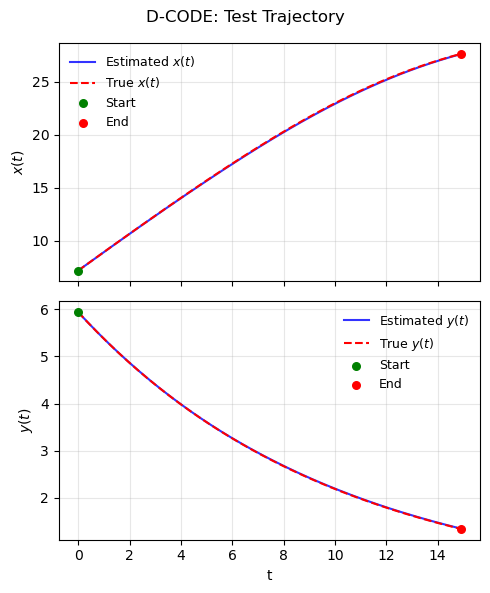

In [8]:
# Simulate a test trajectory starting from an initial condition within the training interval
evaluate_sample = 1
ics = [7., 6., 1.8]
title = 'D-CODE: Test Trajectory'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

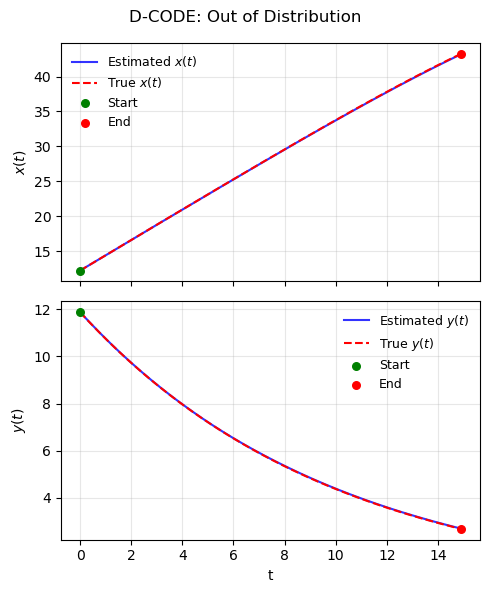

In [9]:
# Simulate a test trajectory starting from an initial condition outside the training interval
evaluate_sample = 1
ics = [12, 12, 2.2]
title = 'D-CODE: Out of Distribution'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=15)

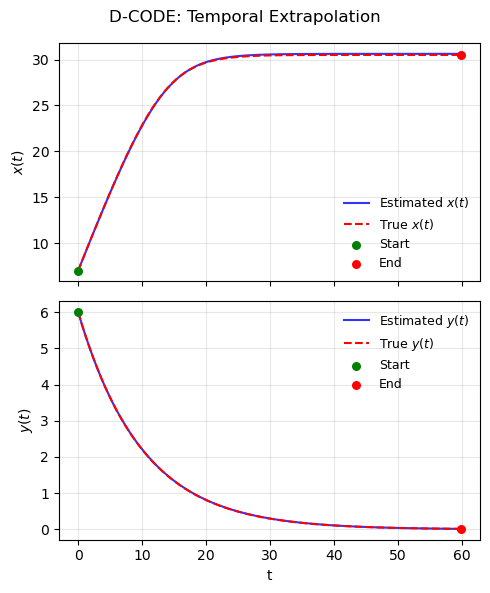

In [10]:
# Simulate a test trajectory starting from an initial condition within the training interval 
# but with focus on a longer extrapolation time
evaluate_sample = 1
ics = [7, 6, 1.8]
title = 'D-CODE: Temporal Extrapolation'
evaluate_traj(model, ode, freq, evaluate_sample, ics, ics, dim_x, dim_k, title=title, T_aux=60)